# LAB 10 - Fine-tune DistilBERT cho Extractive QA trên SQuAD

**Chạy trên Google Colab:** Runtime → Change runtime type → **T4 GPU**. Upload `qa_model.py` và `document_qa.py` vào cùng thư mục với notebook, rồi Runtime → Run all (khoảng 1 - 1.5 giờ). Xong thì tải về: notebook này, `results.csv`, `learning_curves.png`, `em_f1_analysis.png`, `answer_length_analysis.png`. `results.csv` được ghi lại sau mỗi phần, nên nếu Colab bị ngắt thì phần đã chạy vẫn còn.

- **Model:** `distilbert-base-cased`, thêm head Linear $d \to 2$ cho mỗi token (một logit start, một logit end).
- **Train:** toàn bộ SQuAD v1.1 train, trừ khoảng 2K câu hỏi giữ lại làm validation (tách theo bài viết để không trùng context).
- **Test:** toàn bộ SQuAD validation (10,570 câu hỏi), vì SQuAD không công bố tập test.

In [1]:
import os
import sys
sys.path.insert(0, os.getcwd())
from qa_model import (IS_LOCAL, MODEL_NAME, baseline_answer, evaluate, f1_score, load_squad,      # import trước transformers
                      postprocess, prepare_eval_features, prepare_train_features, score)

import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForQuestionAnswering, AutoTokenizer, get_linear_schedule_with_warmup

QUICK = os.environ.get("LAB10_QUICK") == "1"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| chạy trên máy:" if IS_LOCAL else "| Colab", IS_LOCAL if IS_LOCAL else "")
if not IS_LOCAL and DEVICE == "cpu":
    raise RuntimeError("Chưa bật GPU: vào Runtime → Change runtime type → chọn T4 GPU, rồi chạy lại.")
FP16 = DEVICE == "cuda"
MAX_LEN, STRIDE, BATCH, LR, EPOCHS, WARMUP, SEED = 384, 128, 32, 3e-5, 2, 0.1, 42
EXP1_N, EXP1_LENS = 20000, [(128, 42), (256, 85), (384, 128)]
N_VAL, EVALS_PER_EPOCH, N_CTRL = 2000, 4, 1000
SAVE_DIR = os.path.join(os.environ["HF_HOME"], "lab10_qa_model") if IS_LOCAL else "lab10_qa_model"
if QUICK:
    EPOCHS, EXP1_N, N_VAL, EVALS_PER_EPOCH, N_CTRL = 1, 160, 60, 2, 60
    SAVE_DIR += "_quick"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 110)

# chia train / validation theo bài viết (title)
squad_train, test = load_squad("train"), load_squad("validation")
titles = np.array(squad_train.title.unique(), dtype=object)
np.random.default_rng(SEED).shuffle(titles)
val_titles, n = set(), 0
for t in titles:
    if n >= N_VAL:
        break
    val_titles.add(t); n += (squad_train.title == t).sum()
val = squad_train[squad_train.title.isin(val_titles)].sample(N_VAL, random_state=SEED).reset_index(drop=True)
train = squad_train[~squad_train.title.isin(val_titles)].reset_index(drop=True)
if QUICK:
    train, test = train.sample(400, random_state=SEED).reset_index(drop=True), test.sample(200, random_state=SEED).reset_index(drop=True)
gold_test = test.answers.tolist()

RESULTS = []
def log(experiment, model, setting, metric, value):
    RESULTS.append({"experiment": experiment, "model": model, "setting": setting, "metric": metric, "value": value})
def save_results():
    pd.DataFrame(RESULTS).to_csv("results.csv", index=False)

hardware = (f"GPU {torch.cuda.get_device_name(0)}, fp16" if DEVICE == "cuda" else f"CPU {platform.processor()}, {torch.get_num_threads()} threads")
repro = {"Model": f"{MODEL_NAME} (6 layer, hidden 768)", "Tokenizer": f"{MODEL_NAME} (WordPiece cased)",
         "Dataset": "SQuAD v1.1 (rajpurkar/squad)",
         "Train / validation / test": f"{len(train)} / {len(val)} / {len(test)} câu hỏi",
         "Max sequence length / stride": f"{MAX_LEN} / {STRIDE}", "Batch size": BATCH, "Learning rate": LR, "Epochs": EPOCHS,
         "Optimizer": "AdamW (weight decay 0.01), linear warmup 10% + decay, clip 1.0", "Random seed": SEED, "Hardware": hardware,
         "torch": torch.__version__}
pd.Series(repro)

Device: cuda | Colab 


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

,0
Model,"distilbert/distilbert-base-cased (6 layer, hidden 768)"
Tokenizer,distilbert/distilbert-base-cased (WordPiece cased)
Dataset,SQuAD v1.1 (rajpurkar/squad)
Train / validation / test,85548 / 2000 / 10570 câu hỏi
Max sequence length / stride,384 / 128
Batch size,32
Learning rate,0.00003
Epochs,2
Optimizer,"AdamW (weight decay 0.01), linear warmup 10% + decay, clip 1.0"
Random seed,42


## 1. Tokenize với sliding window và gán start / end

Chi tiết từng bước nằm trong `tokenizer_alignment.ipynb` và `qa_model.py`. Ở đây chỉ in một window để thấy đủ các thành phần.

In [2]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
r = test.iloc[0]
enc = tok(r.question, r.context, truncation="only_second", max_length=MAX_LEN, stride=STRIDE,
          return_overflowing_tokens=True, return_offsets_mapping=True)
f = prepare_train_features(tok, [r.question], [r.context], [r.starts[0]], [r.answers[0]], MAX_LEN, STRIDE)
s, e = f["start_positions"][0], f["end_positions"][0]
print("question:", r.question, "| gold:", r.answers[0], "| answer_start (ký tự):", r.starts[0])
print("keys:", list(enc.keys()))
print("input_ids[:12]:", enc["input_ids"][0][:12], "| attention_mask[:12]:", enc["attention_mask"][0][:12])
print("offset_mapping[:12]:", enc["offset_mapping"][0][:12])
print("overflow_to_sample_mapping:", enc["overflow_to_sample_mapping"])
print(f"start / end token: {s} / {e} → offsets {enc['offset_mapping'][0][s]} - {enc['offset_mapping'][0][e]} "
      f"→ context[{enc['offset_mapping'][0][s][0]}:{enc['offset_mapping'][0][e][1]}] = "
      f"{r.context[enc['offset_mapping'][0][s][0]:enc['offset_mapping'][0][e][1]]!r}")

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

question: Which NFL team represented the AFC at Super Bowl 50? | gold: Denver Broncos | answer_start (ký tự): 177
keys: ['input_ids', 'token_type_ids', 'attention_mask', 'offset_mapping', 'overflow_to_sample_mapping']
input_ids[:12]: [101, 5979, 4279, 1264, 2533, 1103, 10402, 1120, 3198, 5308, 1851, 136] | attention_mask[:12]: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
offset_mapping[:12]: [(0, 0), (0, 5), (6, 9), (10, 14), (15, 26), (27, 30), (31, 34), (35, 37), (38, 43), (44, 48), (49, 51), (51, 52)]
overflow_to_sample_mapping: [0]
start / end token: 46 / 47 → offsets (177, 183) - (184, 191) → context[177:191] = 'Denver Broncos'


In [3]:
def train_feats(df, L=MAX_LEN, S=STRIDE):
    return prepare_train_features(tok, df.question, df.context, [x[0] for x in df.starts], [a[0] for a in df.answers], L, S)

def batches(lengths, bs, rng=None):
    """Xáo trộn rồi sắp theo độ dài trong từng nhóm 50 batch (giảm padding). rng=None: giữ thứ tự theo độ dài."""
    idx = np.argsort(lengths) if rng is None else rng.permutation(len(lengths))
    if rng is not None:
        mega = bs * 50
        idx = np.concatenate([sorted(idx[i:i + mega], key=lambda j: lengths[j]) for i in range(0, len(idx), mega)])
    out = [idx[i:i + bs] for i in range(0, len(idx), bs)]
    if rng is not None:
        rng.shuffle(out)
    return out

def collate(feats, idx, labels=True):
    ids = [feats["input_ids"][i] for i in idx]
    L = max(map(len, ids))
    x = {"input_ids": torch.tensor([a + [tok.pad_token_id] * (L - len(a)) for a in ids], device=DEVICE),
         "attention_mask": torch.tensor([[1] * len(a) + [0] * (L - len(a)) for a in ids], device=DEVICE)}
    if labels:
        x["start_positions"] = torch.tensor([feats["start_positions"][i] for i in idx], device=DEVICE)
        x["end_positions"] = torch.tensor([feats["end_positions"][i] for i in idx], device=DEVICE)
    return x

@torch.no_grad()
def logits_of(model, feats, bs=64):
    model.eval()
    S, E = [None] * len(feats["input_ids"]), [None] * len(feats["input_ids"])
    for b in batches([len(a) for a in feats["input_ids"]], bs):
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=FP16):
            out = model(**collate(feats, b, labels=False))
        for k, i in enumerate(b):
            n = len(feats["input_ids"][i])
            S[i], E[i] = out.start_logits[k, :n].float().cpu().numpy(), out.end_logits[k, :n].float().cpu().numpy()
    return S, E

@torch.no_grad()
def loss_of(model, feats, bs=64):
    model.eval()
    tot, n = 0.0, 0
    for b in batches([len(a) for a in feats["input_ids"]], bs):
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=FP16):
            tot += model(**collate(feats, b)).loss.item() * len(b)        # loss = (L_start + L_end) / 2
        n += len(b)
    return tot / n

def predict(model, df, L=MAX_LEN, S=STRIDE):
    feats = prepare_eval_features(tok, df.question, df.context, L, S)
    sl, el = logits_of(model, feats)
    return postprocess(sl, el, feats, list(df.context))

def train_model(df, L=MAX_LEN, S=STRIDE, epochs=EPOCHS, eval_df=None, evals_per_epoch=0, tag=""):
    torch.manual_seed(SEED)
    model = AutoModelForQuestionAnswering.from_pretrained(MODEL_NAME).to(DEVICE)
    feats = train_feats(df, L, S)
    lengths = [len(a) for a in feats["input_ids"]]
    steps_per_epoch = (len(lengths) + BATCH - 1) // BATCH
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * epochs * steps_per_epoch), epochs * steps_per_epoch)
    scaler = torch.amp.GradScaler("cuda", enabled=FP16)
    if eval_df is not None:
        eval_feats = train_feats(eval_df, L, S)
        eval_at = {int(steps_per_epoch * k / evals_per_epoch) for k in range(1, evals_per_epoch + 1)}
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    rng, hist, t0 = np.random.default_rng(SEED), [], time.perf_counter()
    print(f"[{tag}] {len(df)} câu hỏi → {len(lengths)} window, {steps_per_epoch} step/epoch", flush=True)
    for ep in range(epochs):
        run, run_n = 0.0, 0
        for step, b in enumerate(batches(lengths, BATCH, rng), 1):
            model.train()
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=FP16):
                loss = model(**collate(feats, b)).loss
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run, run_n = run + loss.item(), run_n + 1
            if eval_df is not None and step in eval_at:
                m, _ = evaluate([p["text"] for p in predict(model, eval_df, L, S)], eval_df.answers.tolist())
                hist.append({"epoch": ep + step / steps_per_epoch, "train_loss": run / run_n, "val_loss": loss_of(model, eval_feats),
                             "val_EM": m["EM"], "val_F1": m["F1"], "time_min": (time.perf_counter() - t0) / 60})
                print(f"  epoch {hist[-1]['epoch']:.2f}: train_loss {hist[-1]['train_loss']:.3f} val_loss {hist[-1]['val_loss']:.3f} "
                      f"val EM {m['EM']:.1f} F1 {m['F1']:.1f} ({hist[-1]['time_min']:.1f} phút)", flush=True)
                run, run_n = 0.0, 0
    train_time = time.perf_counter() - t0
    mem = torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else float("nan")
    return model, hist, train_time, mem

## 2. Baseline: keyword overlap

Chọn câu trong context có nhiều từ trùng với câu hỏi nhất, rồi lấy cụm từ không có trong câu hỏi nằm gần các từ trùng (`qa_model.baseline_answer`). Câu hỏi when / how many ưu tiên cụm có chữ số.

In [4]:
t0 = time.perf_counter()
base_pred = [baseline_answer(q, c) for q, c in zip(test.question, test.context)]
base_m, base_s = evaluate(base_pred, gold_test)
print(f"Baseline: EM {base_m['EM']:.2f} | F1 {base_m['F1']:.2f} ({time.perf_counter() - t0:.0f} s)")
for k, v in base_m.items():
    log("exp3_em_f1", "Baseline", "test", k, v)
save_results()

Baseline: EM 8.92 | F1 22.39 (4 s)


## 3. Experiment 2 - Fine-tune pretrained Transformer + learning curves

In [5]:
model, hist, tf_train_time, tf_mem = train_model(train, eval_df=val, evals_per_epoch=EVALS_PER_EPOCH, tag="main")
print(f"train {tf_train_time / 60:.1f} phút, GPU memory peak {tf_mem:.0f} MB")
model.save_pretrained(SAVE_DIR); tok.save_pretrained(SAVE_DIR)
H = pd.DataFrame(hist)
for _, h in H.iterrows():
    for k in ["train_loss", "val_loss", "val_EM", "val_F1"]:
        log("exp2_learning_curve", "Transformer", f"epoch={h.epoch:.2f}", k, h[k])
log("exp2_learning_curve", "Transformer", "-", "train_time_s", tf_train_time)
save_results()
H.round(3)

model.safetensors:   0%|          | 0.00/263M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert/distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
qa_outputs.bias         | MISSING    | 
qa_outputs.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[main] 85548 câu hỏi → 86664 window, 2709 step/epoch
  epoch 0.25: train_loss 3.114 val_loss 1.972 val EM 42.9 F1 56.7 (1.7 phút)
  epoch 0.50: train_loss 1.683 val_loss 1.505 val EM 53.4 F1 68.0 (3.6 phút)
  epoch 0.75: train_loss 1.408 val_loss 1.371 val EM 56.8 F1 70.7 (5.4 phút)
  epoch 1.00: train_loss 1.316 val_loss 1.327 val EM 57.0 F1 71.1 (7.3 phút)
  epoch 1.25: train_loss 1.061 val_loss 1.322 val EM 57.6 F1 71.9 (9.1 phút)
  epoch 1.50: train_loss 1.029 val_loss 1.281 val EM 59.3 F1 73.4 (11.0 phút)
  epoch 1.75: train_loss 1.021 val_loss 1.268 val EM 59.6 F1 73.6 (12.8 phút)
  epoch 2.00: train_loss 0.980 val_loss 1.247 val EM 60.0 F1 73.9 (14.7 phút)
train 14.7 phút, GPU memory peak 3612 MB


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,epoch,train_loss,val_loss,val_EM,val_F1,time_min
0,0.25,3.114,1.972,42.90,56.710,1.740
1,0.50,1.683,1.505,53.45,67.970,3.595
2,0.75,1.408,1.371,56.80,70.677,5.415
3,1.00,1.316,1.327,56.95,71.069,7.281
4,1.25,1.061,1.322,57.55,71.873,9.132
5,1.50,1.029,1.281,59.30,73.371,10.958
6,1.75,1.021,1.268,59.55,73.565,12.836
7,2.00,0.980,1.247,60.00,73.943,14.653


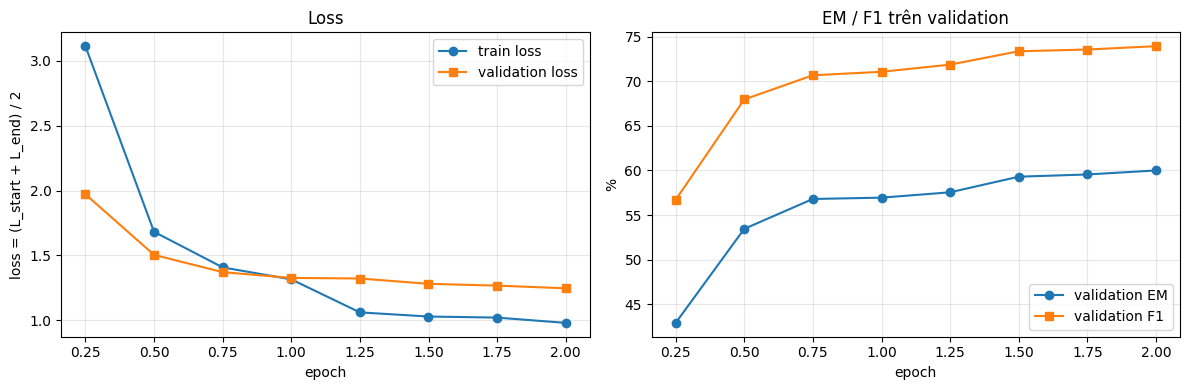

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(H.epoch, H.train_loss, "o-", label="train loss")
axes[0].plot(H.epoch, H.val_loss, "s-", label="validation loss")
axes[0].set(xlabel="epoch", ylabel="loss = (L_start + L_end) / 2", title="Loss")
axes[1].plot(H.epoch, H.val_EM, "o-", label="validation EM")
axes[1].plot(H.epoch, H.val_F1, "s-", label="validation F1")
axes[1].set(xlabel="epoch", ylabel="%", title="EM / F1 trên validation")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("learning_curves.png", dpi=120); plt.show()

In [7]:
t0 = time.perf_counter()
tf_pred_full = predict(model, test)
tf_infer = time.perf_counter() - t0
tf_pred = [p["text"] for p in tf_pred_full]
tf_m, tf_s = evaluate(tf_pred, gold_test)
print(f"Transformer trên test: EM {tf_m['EM']:.2f} | F1 {tf_m['F1']:.2f} (inference {tf_infer:.0f} s)")
for k, v in tf_m.items():
    log("exp3_em_f1", "Transformer", "test", k, v)
log("exp3_em_f1", "Transformer", "test", "infer_time_s", tf_infer)
save_results()

Transformer trên test: EM 74.64 | F1 82.95 (inference 30 s)


**Nhận xét Exp 2 (learning curve)**

- Train loss giảm nhanh trong 1/4 epoch đầu (3.11 → 1.68), sau đó chậm lại. Val loss giảm đều đến hết epoch 2 (1.25), val F1 tăng từ 56.7 lên 73.9.
- Không thấy overfitting: val loss vẫn còn giảm. Khoảng cách train/val (0.98 so với 1.25) nhỏ. Có thể train thêm epoch 3 nhưng lợi ích còn ít (epoch 2 chỉ thêm khoảng 3 F1).
- Val F1 (73.9) thấp hơn test F1 (82.9) vì val tách từ train chỉ có **1** đáp án gold, còn test (SQuAD dev) có khoảng 3 đáp án, và metric lấy max.
- Train 2 epoch trên T4 mất 14.7 phút, GPU memory peak 3.6 GB.

## 4. Experiment 3 - EM vs F1

,EM,F1
Baseline,8.92,22.39
Transformer,74.64,82.95


,Baseline,Transformer
EM = 1,8.9,74.6
"EM = 0, F1 > 0",25.7,15.0
F1 = 0,65.3,10.3


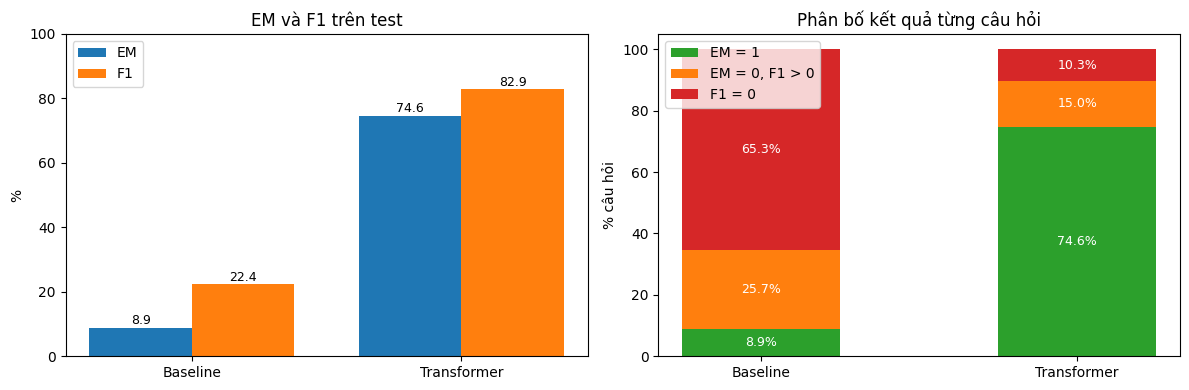

In [8]:
def outcome(s):
    return np.where(s[:, 0] == 1, "EM = 1", np.where(s[:, 1] > 0, "EM = 0, F1 > 0", "F1 = 0"))

cats = ["EM = 1", "EM = 0, F1 > 0", "F1 = 0"]
out_tab = pd.DataFrame({name: pd.Series(outcome(s)).value_counts(normalize=True).reindex(cats).fillna(0) * 100
                        for name, s in [("Baseline", base_s), ("Transformer", tf_s)]})
display(pd.DataFrame({"Baseline": base_m, "Transformer": tf_m}).T.round(2))
display(out_tab.round(1))
for name, col in out_tab.items():
    for c, v in col.items():
        log("exp3_em_f1", name, c, "% câu hỏi", v)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(2)
for k, metric in enumerate(["EM", "F1"]):
    v = [base_m[metric], tf_m[metric]]
    axes[0].bar(x + (k - 0.5) * 0.38, v, 0.38, label=metric)
    for xi, vi in zip(x, v):
        axes[0].text(xi + (k - 0.5) * 0.38, vi + 1, f"{vi:.1f}", ha="center", fontsize=9)
axes[0].set_xticks(x, ["Baseline", "Transformer"]); axes[0].set(ylabel="%", title="EM và F1 trên test", ylim=(0, 100)); axes[0].legend()
bottom = np.zeros(2)
for c, color in zip(cats, ["tab:green", "tab:orange", "tab:red"]):
    v = out_tab.loc[c].values
    axes[1].bar(x, v, 0.5, bottom=bottom, label=c, color=color)
    for xi, vi, bi in zip(x, v, bottom):
        axes[1].text(xi, bi + vi / 2, f"{vi:.1f}%", ha="center", va="center", fontsize=9, color="white")
    bottom += v
axes[1].set_xticks(x, ["Baseline", "Transformer"]); axes[1].set(ylabel="% câu hỏi", title="Phân bố kết quả từng câu hỏi"); axes[1].legend(loc="upper left")
plt.tight_layout(); plt.savefig("em_f1_analysis.png", dpi=120); plt.show()

In [9]:
print("Ví dụ EM = 0 nhưng F1 > 0 (Transformer):")
partial = [i for i in range(len(test)) if tf_s[i, 0] == 0 and tf_s[i, 1] > 0]
for i in np.random.default_rng(1).choice(partial, min(8, len(partial)), replace=False):
    best_gold = max(gold_test[i], key=lambda g: f1_score(tf_pred[i], g))
    print(f"  Q: {test.question[i]}\n     gold: {best_gold!r} | pred: {tf_pred[i]!r} | F1 {tf_s[i, 1]:.2f}")

Ví dụ EM = 0 nhưng F1 > 0 (Transformer):
  Q: How did france differ from Britain in managing its colonies?
     gold: 'sent small numbers of settlers to its colonies' | pred: 'sent small numbers of settlers to its colonies, with the only notable exception of Algeria, where French settlers nevertheless always remained a small minority' | F1 0.53
  Q: Was the Use of the DATANET 1 name correct 
     gold: 'the name was incorrect' | pred: 'incorrect' | F1 0.50
  Q: What other CBS talk show played, after the main one that began immediately after Super Bowl 50?
     gold: 'The Late Late Show with James Corden' | pred: 'The Late Show' | F1 0.50
  Q: Who along with Russia supported post WW-II communist movements?
     gold: 'People’s Republic of China' | pred: 'The Soviet Union and the People’s Republic of China' | F1 0.73
  Q: What additional membranes do secondary chloroplasts have?
     gold: "sometimes the eaten alga's cell membrane" | pred: 'double membrane' | F1 0.29
  Q: In the determin

**Nhận xét Exp 3 (EM và F1)**

- Transformer đạt EM 74.6 / F1 82.9, gấp nhiều lần baseline (8.9 / 22.4).
- 15% câu hỏi có EM = 0 nhưng F1 > 0. Model tìm đúng vùng nhưng lệch ranh giới: thừa mệnh đề phụ ("..., with the only notable exception of Algeria"), thiếu một vế ("Charles Brenton Huggins **and Janet Rowley**"), hoặc chọn cách diễn đạt khác ("incorrect" so với "the name was incorrect").
- Vì vậy chỉ nhìn EM sẽ đánh giá thấp model. F1 cho biết model "gần đúng" đến đâu.

## 5. Experiment 4 - Question / context matching

Overlap = tỉ lệ từ nội dung (bỏ stopword) của câu hỏi xuất hiện trong **câu chứa đáp án**. Overlap cao nghĩa là câu hỏi gần như chép lại câu trong context, overlap thấp nghĩa là câu hỏi diễn đạt khác.

In [10]:
from qa_model import STOP, WORD_RE
SENT_RE = __import__("re").compile(r"[^.!?]+[.!?]*")

def answer_sentence(context, start):
    for m in SENT_RE.finditer(context):
        if m.start() <= start < m.end():
            return m.group()
    return context

def overlap_ratio(question, sentence):
    q = {w.lower() for w in WORD_RE.findall(question) if w.lower() not in STOP}
    s = {w.lower() for w in WORD_RE.findall(sentence)}
    return len(q & s) / max(len(q), 1)

test["overlap"] = [overlap_ratio(q, answer_sentence(c, st[0])) for q, c, st in zip(test.question, test.context, test.starts)]
test["overlap_bin"] = pd.cut(test.overlap, [-0.01, 0.4, 0.7, 1.0], labels=["thấp (≤ 0.4)", "trung bình", "cao (> 0.7)"])
rows = []
for b, g in test.groupby("overlap_bin", observed=True):
    i = g.index.values
    rows.append({"overlap": b, "n": len(i), "Baseline EM": 100 * base_s[i, 0].mean(), "Baseline F1": 100 * base_s[i, 1].mean(),
                 "Transformer EM": 100 * tf_s[i, 0].mean(), "Transformer F1": 100 * tf_s[i, 1].mean()})
    for k in ["Baseline", "Transformer"]:
        log("exp4_overlap", k, str(b), "F1", rows[-1][f"{k} F1"])
save_results()
pd.DataFrame(rows).set_index("overlap").round(1)

,n,Baseline EM,Baseline F1,Transformer EM,Transformer F1
overlap,,,,,
thấp (≤ 0.4),3479,3.7,12.5,66.7,75.8
trung bình,3883,8.4,23.0,76.4,84.4
cao (> 0.7),3208,15.2,32.4,81.0,88.9


In [11]:
print("Ví dụ câu hỏi overlap thấp (diễn đạt khác context):")
low = test[test.overlap <= 0.2].index.values
for i in np.random.default_rng(2).choice(low, min(5, len(low)), replace=False):
    print(f"  Q: {test.question[i]}\n     câu chứa đáp án: {answer_sentence(test.context[i], test.starts[i][0]).strip()[:150]!r}\n"
          f"     gold {gold_test[i][0]!r} | Transformer {tf_pred[i]!r} | Baseline {base_pred[i]!r}")

Ví dụ câu hỏi overlap thấp (diễn đạt khác context):
  Q: What other aspect of Luther's life was affected by his health?
     câu chứa đáp án: 'His poor physical health made him short-tempered and even harsher in his writings and comments.'
     gold 'writings and comments' | Transformer 'poor physical' | Baseline 'poor physical'
  Q: Where does Warsaw rank in terms of population in the EU?
     câu chứa đáp án: '666 million residents, which makes Warsaw the 9th most-populous capital city in the European Union.'
     gold '9th' | Transformer '9th' | Baseline 'Polish: Warszawa [varˈʂava] ( listen); see'
  Q: What is the capitol of Kenya?
     câu chứa đáp án: 'Its capital and largest city is Nairobi.'
     gold 'Nairobi' | Transformer 'Nairobi' | Baseline 'ˈkɛnjə/; locally [ˈkɛɲa] ( listen)), officially'
  Q: Whose saying about freeing souls from purgatory was often quoted?
     câu chứa đáp án: 'However, this oft-quoted saying of Tetzel was by no means representative of contemporary Cat

**Nhận xét Exp 4 (lexical overlap)**

- Cả hai model đều tốt hơn khi câu hỏi trùng nhiều từ với câu chứa đáp án. Transformer: 75.8 → 88.9 F1. Baseline: 12.5 → 32.4.
- Baseline phụ thuộc hoàn toàn vào trùng từ, nên ở nhóm overlap thấp chỉ còn 12.5 F1. Transformer vẫn đạt 75.8 nhờ hiểu paraphrase ("capitol" → capital, "rank in terms of population" → "most-populous").
- Tuy vậy, chênh lệch 13 điểm F1 cho thấy model **vẫn dựa một phần vào trùng từ**. Ví dụ "What other aspect... affected by his health?": cả hai model chọn "poor physical" (gần từ "health") thay vì "writings and comments".

## 6. Experiment 5 - Độ dài answer

,n,Baseline EM,Baseline F1,Transformer EM,Transformer F1
answer length,,,,,
1,3429,12.5,23.5,79.8,84.6
2-3,4575,8.3,22.4,76.9,84.2
4-6,1648,7.3,21.2,70.1,82.6
7+,918,1.5,20.2,52.2,71.0


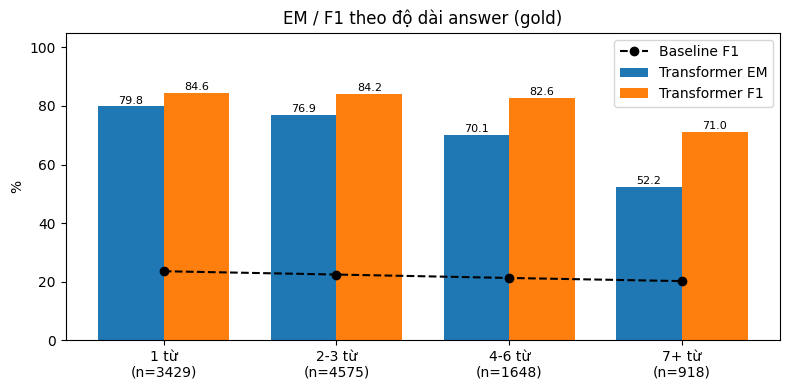

In [12]:
def len_bin(n):
    return "1" if n == 1 else "2-3" if n <= 3 else "4-6" if n <= 6 else "7+"

test["ans_len"] = [len(a[0].split()) for a in test.answers]
test["len_bin"] = test.ans_len.map(len_bin)
rows = []
for b in ["1", "2-3", "4-6", "7+"]:
    i = test.index[test.len_bin == b].values
    rows.append({"answer length": b, "n": len(i), "Baseline EM": 100 * base_s[i, 0].mean(), "Baseline F1": 100 * base_s[i, 1].mean(),
                 "Transformer EM": 100 * tf_s[i, 0].mean(), "Transformer F1": 100 * tf_s[i, 1].mean()})
    for k in ["Baseline", "Transformer"]:
        for m in ["EM", "F1"]:
            log("exp5_answer_length", k, f"len={b}", m, rows[-1][f"{k} {m}"])
save_results()
len_df = pd.DataFrame(rows).set_index("answer length")
display(len_df.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(len_df))
for k, (col, lab) in enumerate([("Transformer EM", "Transformer EM"), ("Transformer F1", "Transformer F1")]):
    ax.bar(x + (k - 0.5) * 0.38, len_df[col], 0.38, label=lab)
    for xi, vi in zip(x, len_df[col]):
        ax.text(xi + (k - 0.5) * 0.38, vi + 1, f"{vi:.1f}", ha="center", fontsize=8)
ax.plot(x, len_df["Baseline F1"], "k--o", label="Baseline F1")
ax.set_xticks(x, [f"{b} từ\n(n={n})" for b, n in zip(len_df.index, len_df.n)])
ax.set(ylabel="%", title="EM / F1 theo độ dài answer (gold)", ylim=(0, 105)); ax.legend()
plt.tight_layout(); plt.savefig("answer_length_analysis.png", dpi=120); plt.show()

**Nhận xét Exp 5 (độ dài answer)**

- Answer càng dài càng khó. EM giảm từ 79.8 (1 từ) xuống 52.2 (7+ từ), tức −27.6. F1 chỉ giảm từ 84.6 xuống 71.0, tức −13.6.
- EM giảm gấp đôi F1 vì answer dài có nhiều cách cắt hợp lý. Lệch một từ là EM = 0, nhưng F1 vẫn được điểm phần trùng.
- Baseline gần như không bao giờ đúng nguyên văn answer dài (EM 1.5).

## 7. Thí nghiệm có kiểm soát: thông tin nhiễu, câu gây nhiễu, đổi thứ tự câu (Prediction 3, 4)

Lấy ngẫu nhiên các câu hỏi trong test mà đáp án nằm gọn trong một câu và context có ít nhất 3 câu. Mỗi câu hỏi được thử với 4 phiên bản context, đáp án gold giữ nguyên:

- **original:** context gốc.
- **+ irrelevant:** thêm vào cuối một câu lấy từ bài viết khác.
- **+ distractor:** thêm vào cuối một câu chép lại câu hỏi nhưng thay từ để hỏi bằng một đáp án sai cùng loại. Ví dụ "What is the capital of France?" thành "Berlin is the capital of France."
- **reordered:** xáo trộn thứ tự các câu.

In [13]:
import re
SPLIT_RE = re.compile(r"(?<=[.!?])\s+(?=[A-Z\"'(])")
WH = re.compile(r"^(?:in |on |at |for |by |during |from |to )?(?:what|which|who|whom|whose|when|where|why|how(?: many| much| long| old| far)?)\b", re.I)

def sentences(context):
    out, pos = [], 0
    for part in SPLIT_RE.split(context):
        s = context.index(part, pos); out.append((s, s + len(part))); pos = s + len(part)
    return out

rng_c = np.random.default_rng(SEED)
cands = []
for i, r in test.iterrows():
    sp = sentences(r.context)
    a, b = r.starts[0], r.starts[0] + len(r.answers[0])
    k = [j for j, (s, e) in enumerate(sp) if s <= a and b <= e]
    if len(sp) >= 3 and k and WH.match(r.question):
        cands.append((i, sp, k[0]))
ctrl_idx = [cands[j] for j in rng_c.choice(len(cands), min(N_CTRL, len(cands)), replace=False)]
wh_of = lambda q: WH.match(q).group().lower()
pool = {}
for i, r in test.iterrows():
    if WH.match(r.question):
        pool.setdefault(wh_of(r.question), []).append((r.title, r.answers[0]))
other_sents = [s.strip() for c in test.context.unique() for s in SPLIT_RE.split(c) if 40 < len(s) < 200]

variants = {"original": [], "+ irrelevant": [], "+ distractor": [], "reordered": []}
fake_answers = []
for i, sp, k in ctrl_idx:
    r = test.loc[i]
    variants["original"].append(r.context)
    title = r.title
    while True:
        s = other_sents[rng_c.integers(len(other_sents))]
        if s not in r.context:
            break
    variants["+ irrelevant"].append(r.context + " " + s)
    same_type = [a for t, a in pool[wh_of(r.question)] if t != title and score(a, r.answers)[1] == 0]   # đáp án sai cùng loại câu hỏi
    if not same_type:                                                                                     # loại câu hỏi hiếm: lấy đáp án bất kỳ
        same_type = [a for t, a in sum(pool.values(), []) if t != title and score(a, r.answers)[1] == 0]
    fake = same_type[rng_c.integers(len(same_type))]
    fake_answers.append(fake)
    rest = WH.sub("", r.question, count=1).strip().rstrip("?").strip()
    variants["+ distractor"].append(r.context + " " + f"{fake} {rest}.")
    order = rng_c.permutation(len(sp))
    while (order == np.arange(len(sp))).all():
        order = rng_c.permutation(len(sp))
    variants["reordered"].append(" ".join(r.context[sp[j][0]:sp[j][1]] for j in order))

ctrl = test.loc[[i for i, _, _ in ctrl_idx]].reset_index(drop=True)
print(f"{len(ctrl)} câu hỏi. Ví dụ distractor:\n  Q: {ctrl.question[0]}\n  câu thêm: {variants['+ distractor'][0][len(ctrl.context[0]):].strip()!r}")

1000 câu hỏi. Ví dụ distractor:
  Q: What are both Branko Milanovic and Joseph Stiglitz?
  câu thêm: "Grand Canal d'Alsace are both Branko Milanovic and Joseph Stiglitz."


In [14]:
rows = []
for name, ctxs in variants.items():
    df = ctrl.assign(context=ctxs)
    p_full = predict(model, df)
    p = [x["text"] for x in p_full]
    m, s = evaluate(p, ctrl.answers.tolist())
    bm, _ = evaluate([baseline_answer(q, c) for q, c in zip(df.question, df.context)], ctrl.answers.tolist())
    row = {"context": name, "Transformer EM": m["EM"], "Transformer F1": m["F1"], "Baseline F1": bm["F1"]}
    if name in ("+ irrelevant", "+ distractor"):
        row["% đáp án nằm trong câu thêm"] = 100 * np.mean([x["start_char"] >= len(c) for x, c in zip(p_full, ctrl.context)])
    rows.append(row)
    for k in ["Transformer EM", "Transformer F1", "Baseline F1"]:
        log("controlled_context", k.split()[0], name, k.split()[1], row[k])
save_results()
ctrl_df = pd.DataFrame(rows).set_index("context")
ctrl_df.round(1)

,Transformer EM,Transformer F1,Baseline F1,% đáp án nằm trong câu thêm
context,,,,
original,79.1,86.6,22.8,NaN
+ irrelevant,78.5,86.1,22.8,0.3
+ distractor,21.1,23.7,4.8,75.2
reordered,77.1,84.7,22.7,NaN


**Nhận xét controlled test (1000 câu hỏi)**

- **+ irrelevant:** F1 chỉ giảm 0.5. Model gần như bỏ qua câu không liên quan (chỉ 0.3% đáp án rơi vào câu này).
- **reordered:** F1 giảm 1.9. Đáp án thường nằm trong một câu nên thứ tự câu ít ảnh hưởng. Phần giảm đến từ câu hỏi cần ngữ cảnh câu trước (đại từ, "these defections").
- **+ distractor:** F1 sụp từ 86.6 xuống **23.7**, và 75% đáp án nằm trong câu gây nhiễu. Câu nhiễu chứa gần như toàn bộ từ của câu hỏi cộng với một đáp án đúng loại, nên model chọn nó. Đây là bằng chứng rõ nhất cho thấy model học mẹo "tìm chỗ trùng từ với câu hỏi" chứ không thật sự kiểm tra thông tin. Baseline cũng giảm (22.8 → 4.8).

## 8. Error analysis: wrong start vs wrong end

Với mỗi câu hỏi có EM = 0, so sánh span dự đoán (theo ký tự) với span gold gần nhất (gold có F1 cao nhất):

- **wrong start:** end đúng, start sai.
- **wrong end:** start đúng, end sai.
- **wrong boundary:** cả hai đầu sai nhưng vẫn chồng lấn với gold.
- **wrong span:** không chồng lấn. Chia tiếp thành cùng câu với gold, hoặc ở câu khác (có thể do distractor).

In [15]:
def norm_edge(text, a, b):
    """Bỏ khoảng trắng / dấu câu / mạo từ ở hai đầu span để so ranh giới công bằng như EM."""
    while a < b and (text[a] in " ,.;:!?\"'()" ):
        a += 1
    while b > a and (text[b - 1] in " ,.;:!?\"'()"):
        b -= 1
    m = re.match(r"(?i)(the|a|an)\s+", text[a:b])
    if m:
        a += m.end()
    return a, b

err_rows = []
for i in range(len(test)):
    if tf_s[i, 0] == 1:
        continue
    r, p = test.iloc[i], tf_pred_full[i]
    k = max(range(len(r.answers)), key=lambda j: f1_score(p["text"], r.answers[j]))
    gs, ge = norm_edge(r.context, r.starts[k], r.starts[k] + len(r.answers[k]))
    ps, pe = norm_edge(r.context, p["start_char"], p["end_char"])
    if ps == gs and pe != ge:
        t = "wrong end"
    elif pe == ge and ps != gs:
        t = "wrong start"
    elif ps < ge and gs < pe:
        t = "wrong boundary"
    else:
        same = answer_sentence(r.context, gs) == answer_sentence(r.context, max(ps, 0))
        t = "wrong span (cùng câu)" if same else "wrong span (câu khác)"
    err_rows.append({"i": i, "type": t, "start_wrong": ps != gs, "end_wrong": pe != ge, "F1": tf_s[i, 1],
                     "pred_longer": (pe - ps) > (ge - gs), "question": r.question, "gold": r.answers[k], "pred": p["text"]})
ERR = pd.DataFrame(err_rows)
print(f"{len(ERR)} câu hỏi sai (EM = 0) trên {len(test)}")
print(f"#wrong start (start sai, tính cả các loại) = {ERR.start_wrong.sum()} | #wrong end = {ERR.end_wrong.sum()}")
for t, n in ERR.type.value_counts().items():
    log("error_analysis", "Transformer", t, "count", n)
log("error_analysis", "Transformer", "all", "wrong_start", ERR.start_wrong.sum())
log("error_analysis", "Transformer", "all", "wrong_end", ERR.end_wrong.sum())
save_results()
display(ERR.groupby("type").agg(n=("i", "size"), mean_F1=("F1", "mean"), pred_dài_hơn_gold=("pred_longer", "mean")).round(2))

2681 câu hỏi sai (EM = 0) trên 10570
#wrong start (start sai, tính cả các loại) = 2103 | #wrong end = 2016


,n,mean_F1,pred_dài_hơn_gold
type,,,
wrong boundary,111,0.43,0.68
wrong end,578,0.57,0.59
wrong span (câu khác),712,0.08,0.42
wrong span (cùng câu),615,0.06,0.47
wrong start,665,0.62,0.60


In [16]:
rng_e = np.random.default_rng(3)
for t in ["wrong start", "wrong end", "wrong boundary", "wrong span (cùng câu)", "wrong span (câu khác)"]:
    sub = ERR[ERR.type == t]
    print(f"\n===== {t}: {len(sub)} =====")
    for _, e in sub.iloc[rng_e.choice(len(sub), min(7, len(sub)), replace=False)].iterrows():
        print(f"  Q: {e.question}\n     gold: {e.gold!r} | pred: {e.pred!r} | F1 {e.F1:.2f}")


===== wrong start: 665 =====
  Q: How can any knot be distinctively indicated?
     gold: 'as a connected sum of prime knots' | pred: 'a connected sum of prime knots' | F1 0.91
  Q: What has a Lama determined to do?
     gold: 'be reborn' | pred: 'reborn' | F1 0.67
  Q: What did Luther contend the Jews to be?
     gold: "the devil's people" | pred: 'the chosen people but "the devil\'s people"' | F1 0.57
  Q: When did Tesla patent the motor?
     gold: 'in May 1888' | pred: 'May 1888' | F1 0.80
  Q: Why do these defections occur?
     gold: 'economic or financial factors' | pred: 'because of economic or financial factors' | F1 0.80
  Q: What does the IPCC not do?
     gold: 'carry out research nor does it monitor climate related data' | pred: 'monitor climate related data' | F1 0.57
  Q: When did Martin Luther die?
     gold: '18 February 1546' | pred: '10 November 1483 – 18 February 1546' | F1 0.60

===== wrong end: 578 =====
  Q: What did lane and vail finance?
     gold: "an electri

**Nhận xét error analysis**

- 2681 / 10570 câu hỏi có EM = 0. Nhóm lỗi ranh giới (wrong start, wrong end, wrong boundary) gồm 1354 câu, F1 trung bình 0.4 - 0.6. Nhóm lỗi chọn sai hẳn chỗ (wrong span) gồm 1327 câu, F1 khoảng 0.
- #wrong start (2103) và #wrong end (2016) gần bằng nhau. Start sai nhiều hơn một chút: chủ yếu do giới từ, từ nối ở đầu span ("in May 1888", "because of ...", "be reborn"). Gold không thống nhất có lấy các từ này hay không.
- End sai thường do thiếu phần bổ nghĩa ("two-thirds **of its population**", "The Late Show **with Stephen Colbert**").
- Wrong span ở câu khác (712) thường là câu hỏi diễn đạt khác context, hoặc context có nhiều thực thể cùng loại (đội Broncos / Chargers, ngày sinh / ngày mất).

## 9. Experiment 1 - Context length (128 / 256 / 384)

Ba lần train giống hệt nhau (cùng 20K câu hỏi train, 1 epoch, cùng seed), chỉ khác max_length. Stride bằng khoảng 1/3 max_length. Đánh giá trên toàn bộ test.

In [17]:
exp1_train = train.sample(min(EXP1_N, len(train)), random_state=SEED).reset_index(drop=True)
rows = []
for L, S in EXP1_LENS:
    m1, _, t_train, mem = train_model(exp1_train, L, S, epochs=1, tag=f"max_length {L}")
    t0 = time.perf_counter()
    p = predict(m1, test, L, S)
    t_inf = time.perf_counter() - t0
    mm, _ = evaluate([x["text"] for x in p], gold_test)
    n_win = len(prepare_eval_features(tok, test.question, test.context, L, S)["input_ids"])
    rows.append({"max_length": L, "stride": S, "EM": mm["EM"], "F1": mm["F1"], "train_time_s": t_train,
                 "infer_time_s": t_inf, "test windows": n_win, "GPU peak MB": mem})
    print(rows[-1], flush=True)
    for k in ["EM", "F1", "train_time_s", "infer_time_s", "GPU peak MB"]:
        log("exp1_context_length", "Transformer", f"max_length={L}", k, rows[-1][k])
    save_results()
    del m1
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
pd.DataFrame(rows).set_index("max_length").round(2)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert/distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
qa_outputs.bias         | MISSING    | 
qa_outputs.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[max_length 128] 20000 câu hỏi → 44322 window, 1386 step/epoch
{'max_length': 128, 'stride': 42, 'EM': np.float64(59.92431409649953), 'F1': np.float64(69.81940150135134), 'train_time_s': 138.33519291099992, 'infer_time_s': 41.2015394670002, 'test windows': 24295, 'GPU peak MB': 2451.87744140625}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert/distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
qa_outputs.bias         | MISSING    | 
qa_outputs.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[max_length 256] 20000 câu hỏi → 22443 window, 702 step/epoch
{'max_length': 256, 'stride': 85, 'EM': np.float64(53.292336802270576), 'F1': np.float64(63.69676185867813), 'train_time_s': 102.18089875700025, 'infer_time_s': 31.134496394000053, 'test windows': 12096, 'GPU peak MB': 3274.50244140625}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert/distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
qa_outputs.bias         | MISSING    | 
qa_outputs.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[max_length 384] 20000 câu hỏi → 20278 window, 634 step/epoch
{'max_length': 384, 'stride': 128, 'EM': np.float64(52.82876064333018), 'F1': np.float64(63.09617176845447), 'train_time_s': 97.41465111900015, 'infer_time_s': 29.53207505799992, 'test windows': 10822, 'GPU peak MB': 4111.23681640625}


,stride,EM,F1,train_time_s,infer_time_s,test windows,GPU peak MB
max_length,,,,,,,
128,42,59.92,69.82,138.34,41.20,24295,2451.88
256,85,53.29,63.70,102.18,31.13,12096,3274.50
384,128,52.83,63.10,97.41,29.53,10822,4111.24


**Nhận xét Exp 1 (context length, 20K câu hỏi, 1 epoch)**

- Ngược với dự đoán: max_length 128 cho F1 cao nhất (69.8), còn 256 và 384 gần bằng nhau (63.7 và 63.1).
- Lý do: thí nghiệm không cân bằng số step. Với 128, mỗi câu hỏi tách thành 2.2 window, nên có 44K window (1386 step) so với 20K window (634 step) ở 384. Model 128 được cập nhật gấp đôi và thấy mỗi đáp án ở nhiều vị trí khác nhau.
- Chi phí: 128 tốn ít GPU memory nhất (2.5 GB so với 4.1 GB), nhưng train và inference chậm nhất (41 s so với 30 s) vì phải chạy nhiều window hơn.
- Muốn so công bằng cần giữ cùng số step. Model chính (384, 2 epoch, full data) vẫn đạt 82.9 F1.

## 10. Application - Document QA

`document_qa.py`: một tài liệu FAQ về học phần (viết lại từ các file đề W8 - W10), dài hơn 384 token, kèm 20 câu hỏi có đáp án gold.

In [18]:
from document_qa import run
doc_m, doc_df = run(SAVE_DIR)
for k, v in doc_m.items():
    log("document_qa", "Transformer", "20 câu hỏi", k, v)
display(doc_df)

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (515 > 512). Running this sequence through the model will result in indexing errors


Tài liệu: 2317 ký tự, 515 token → cần sliding window (max_length 384, stride 128)
EM 75.0 | F1 84.1 trên 20 câu hỏi


,question,gold,prediction,EM,F1
0,Who is the lecturer of the course?,Pham Ngoc Hai,Pham Ngoc Hai,1.0,1.00
1,At which university is the course taught?,VNU University of Science,VNU University of Science,1.0,1.00
2,What time are labs due on the deadline day?,23:59,23:59,1.0,1.00
3,Which dataset is used for sentiment classification in LAB 08?,IMDb,IMDb movie review,0.0,0.86
4,What probability does the model give to eats?,0.70,0.70,1.0,1.00
5,When is LAB 08 due?,"November 11, 2026","November 11, 2026",1.0,1.00
6,Which dataset is used for named entity recognition?,CoNLL-2003,CoNLL-2003,1.0,1.00
7,How many entity types does CoNLL-2003 have?,four,four,1.0,1.00
8,Which labeling scheme is used for entities?,BIO,BIO scheme,1.0,1.00
9,When must LAB 09 be submitted?,"November 18, 2026",23:59,0.0,0.00


## 11. Lưu kết quả

In [19]:
for k, v in repro.items():
    log("setup", "-", k, "value", v)
save_results()
print(len(RESULTS), "dòng đã ghi vào results.csv")

114 dòng đã ghi vào results.csv
